In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import h5py

import matplotlib.patches as patches
fontsize = 7
plt.rcParams.update({
    'font.family': 'Arial',     # or 'Helvetica' if embedded properly
    'font.size': fontsize,
    'pdf.fonttype': 42,         # Embed TrueType (for editable text)
    'ps.fonttype': 42,
    'axes.labelsize': fontsize,
    'xtick.labelsize': fontsize,
    'ytick.labelsize': fontsize,
    'axes.facecolor': 'None',   # transparent background if needed
    'axes.edgecolor': 'black',
    'axes.linewidth': 0.5
})

blue = '#1E88E5'
red = '#FF1D25'

dir0 = "../"
dir1 = dir0+'data/'
dirf = dir0+'figures/'

In [ ]:
def pattern_statistics(k=1, rw= 0.1, theta=1, sigma=0, nsim=10000, seed=42, eps = 0.001):
    rng = np.random.default_rng(seed)  # Set seed
    r1s = rng.uniform(1-rw, 1+rw, size=nsim)
    r2s = rng.uniform(1-rw, 1+rw, size=nsim) 
    a1s = k*(r1s-1) + rng.normal(0, sigma, size=nsim) #interaction budget from species 1
    a2s = k*(r2s-1) + rng.normal(0, sigma, size=nsim)
    outcomes_0d = np.zeros(4)
    outcomes_1d = np.zeros(4)
    outcomes_2d = np.zeros(4)
    a21 = theta*a1s - (1-theta)*a2s # higher your growth rate, stronger you help other species
    a12 = theta*a2s - (1-theta)*a1s

    rf = np.zeros( nsim ); rs = np.zeros( nsim )
    afs = np.zeros( nsim ); asf = np.zeros( nsim )
    for i in np.arange(nsim):
        if(r1s[i] > r2s[i] + eps): # 1 is a faster grower
            rf[i] = r1s[i]; rs[i] = r2s[i]
            afs[i] = a12[i]; asf[i] = a21[i] # facilitation strength
        elif(r2s[i] > r1s[i] + eps): # 2 is a faster grower
            rf[i] = r2s[i]; rs[i] = r1s[i]
            afs[i] = a21[i]; asf[i] = a12[i] # facilitation strength
        else: continue
        ### outcomes
        # 0: composite bulge  / fast win
        # 1: circular bulge / bistability
        # 2: mixed
        # 3: dent / slow win
        dr = rf[i] - rs[i] # difference in growth rate.
        if(asf[i] < dr): # fast not helping slow a lot (left side of PD)
            if(afs[i] < -dr): # slow not helping fast a lot (lower left of PD)
                outcomes_2d[1] += 1 # circular bulge
                outcomes_0d[1] += 1 # bistability
                if(afs[i] > asf[i]-2*dr): outcomes_1d[0] += 1 # fast win
                else: outcomes_1d[3] += 1 # slow win
            elif(afs[i] < 0): # slow is weakly harming fast
                outcomes_2d[1] += 1 # cirucular bulge
                outcomes_1d[0] += 1 # fast win
                outcomes_0d[0] += 1 # fast win
            else: # slow is helping fast
                outcomes_2d[0] += 1 # fast win
                outcomes_1d[0] += 1 # fast win
                outcomes_0d[0] += 1 # fast win
        elif(afs[i] < -dr): # fast helps slow but slow not helps fast (upper left of PD)
            outcomes_2d[3] += 1 # dent
            outcomes_1d[3] += 1 # slow wins
            outcomes_0d[3] += 1 # slow wins
        else: 
            outcomes_2d[2] += 1
            outcomes_1d[2] += 1
            outcomes_0d[2] += 1

    return rf, rs, afs, asf, outcomes_0d/nsim, outcomes_1d/nsim, outcomes_2d/nsim


### 4A

In [6]:
seed = 42
nsim = 100

rfs = np.zeros((3, nsim))
rss = np.zeros((3, nsim))
afss = np.zeros((3, nsim))
asfs = np.zeros((3, nsim))
out0d = np.zeros((3, 4))
out1d = np.zeros((3, 4))
out2d = np.zeros((3, 4))


for i in range(3):
    k = 1.0 + 1.0 *i*1 ; rw=0.1; theta = 1; sigma = 0.01
    rfs[i], rss[i], afss[i], asfs[i], out0d[i], out1d[i], out2d[i] = pattern_statistics(k, rw, theta, sigma, nsim, seed)

/var/folders/v8/_5pczj3j1hxcfl8_d87gmyt80000gn/T/ipykernel_98698/2427800056.py:20: RuntimeWarning: invalid value encountered in divide
  ax.scatter( ( afss[i]/(rfs[i]-rss[i]))[filt]*0.2, (asfs[i]/(rfs[i]-rss[i]))[filt]*0.2 , s=5, linewidth=0., alpha=0.5, color=plt.cm.plasma(i/2.2), zorder=20)


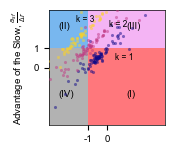

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(1.5,1.5))
        
#ax.set_xlabel('Advantage of the Fast, 'r'$a_{fs}$')
ax.set_ylabel('Advantage of the Slow, 'r'$\frac{a_{sf}}{\Delta r}$')
ax.set_yticks([0, 1*0.2]); ax.set_yticklabels([0, 1])

rect = patches.Rectangle((-0.6, 0.2), 0.4, 0.4, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.6, -0.6), 0.4, 0.8, edgecolor='none', facecolor='grey', alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, -0.6), 0.8, 0.8, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 0.2), 0.8, 0.4, edgecolor='none', facecolor='violet', alpha=0.6)
ax.add_patch(rect)

for i in range(len(afss)):
    filt = (rfs[i] - rss[i] > 1e-3)
    ax.scatter( ( afss[i]/(rfs[i]-rss[i]))[filt]*0.2, (asfs[i]/(rfs[i]-rss[i]))[filt]*0.2 , s=5, linewidth=0., alpha=0.5, color=plt.cm.plasma(i/2.2), zorder=20)
    ax.text( [0.08, 0.08-0.03*2, 0.08-0.2*2][i], [0.08, 0.08+0.2*1.7, 0.08+0.2*2][i], 'k = {}'.format(1+i), color='k', fontsize=6, zorder=20 )
    

ax.set_xticks([-0.2, 0]); ax.set_xticklabels([-1, 0])

ax.set_xlim(-3*0.2, 3*0.2)
ax.set_ylim(-3*0.2, 3*0.2)
fig.savefig(dirf + 'Fig4/4a_PD_0D.pdf', bbox_inches='tight', transparent=True)

/var/folders/v8/_5pczj3j1hxcfl8_d87gmyt80000gn/T/ipykernel_98698/958667322.py:21: RuntimeWarning: invalid value encountered in divide
  ax.scatter( ( afss[i]/(rfs[i]-rss[i]))[filt]*0.2, (asfs[i]/(rfs[i]-rss[i]))[filt]*0.2 , s=5, linewidth=0., alpha=0.5, color=plt.cm.plasma(i/2.2), zorder=20)


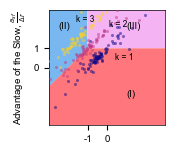

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(1.5,1.5))
        
#ax.set_xlabel('Advantage of the Fast, 'r'$a_{fs}$')
ax.set_ylabel('Advantage of the Slow, 'r'$\frac{a_{sf}}{\Delta r}$')

ax.set_yticks([0, 1*0.2]); ax.set_yticklabels([0,1 ])


# Create a rectangle: (x, y), width, height
wed = patches.Wedge((-0.2, 0.2), 1, 90, 225, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(wed)
wed = patches.Wedge((-0.2, 0.2), 2, 225, 360, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(wed)
rect = patches.Rectangle((-0.2, 0.2), 0.8, 0.4, edgecolor='none', facecolor='violet', alpha=0.6)
ax.add_patch(rect)

for i in range(len(afss)):
    filt = (rfs[i] - rss[i] > 1e-3)
    ax.scatter( ( afss[i]/(rfs[i]-rss[i]))[filt]*0.2, (asfs[i]/(rfs[i]-rss[i]))[filt]*0.2 , s=5, linewidth=0., alpha=0.5, color=plt.cm.plasma(i/2.2), zorder=20)
    ax.text( [0.08, 0.08-0.03*2, 0.08-0.2*2][i], [0.08, 0.08+0.2*1.7, 0.08+0.2*2][i], 'k = {}'.format(1+i), color='k', fontsize=6, zorder=20 )
    

ax.set_xticks([-0.2, 0]); ax.set_xticklabels([-1, 0])

ax.set_xlim(-3*0.2, 3*0.2)
ax.set_ylim(-3*0.2, 3*0.2)
fig.savefig(dirf + 'Fig4/4a_PD_1D.pdf', bbox_inches='tight', transparent=True)

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(1.5,1.5))
        
ax.set_xlabel('Advantage of the Fast, 'r'$\frac{a_{fs}}{\Delta r}$')
ax.set_ylabel('Advantage of the Slow, 'r'$\frac{a_{sf}}{\Delta r}$')

ax.set_yticks([0, 1]); ax.set_yticklabels([0, 1])
ax.set_xticks([-1, 0]); ax.set_xticklabels([-1, 0])

# Create a rectangle: (x, y), width, height
rect = patches.Rectangle((-3, 1), 2, 2, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-3, -3), 3, 4, edgecolor='none', facecolor=red, alpha=0.3)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, -3), 3, 4, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-1, 1), 4, 2, edgecolor='none', facecolor='violet', alpha=0.6)
ax.add_patch(rect)


for i in range(len(afss)):
    filt = (rfs[i] - rss[i] > 1e-3)
    ax.scatter( ( afss[i]/(rfs[i]-rss[i]))[filt], (asfs[i]/(rfs[i]-rss[i]))[filt] , s=5, linewidth=0., alpha=0.5, color=plt.cm.plasma(i/2.2), zorder=20)
    ax.text( [0.4, 0.4-0.15*2, 0.4-1.0*2][i], [0.4, 0.4+0.8*1.7, 0.4+0.8*2][i], 'k = {}'.format(1+i), color='k', fontsize=6, zorder=20 )
    

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
fig.savefig(dirf + 'Fig4/4a_PD_2D.pdf', bbox_inches='tight', transparent=True)

NameError: name 'np' is not defined

### 4B

In [ ]:
## linear, scan over k
np.random.seed(42)
nsim = 10000
outcomes_kbscan_0d = np.zeros((51, 51, 4))
outcomes_kbscan_1d = np.zeros((51, 51, 4))
outcomes_kbscan_2d = np.zeros((51, 51, 4))
rf_scan = np.zeros((51, 51, nsim))
rs_scan = np.zeros((51, 51, nsim))
afs_scan = np.zeros((51, 51, nsim))
asf_scan = np.zeros((51, 51, nsim))
#ss_kbscan = np.zeros((59, 59))
for i in tqdm(np.arange(51)):
    for j in np.arange(51):
        _, _, _, _, outcomes_kbscan_0d[i, j], outcomes_kbscan_1d[i, j], outcomes_kbscan_2d[i, j] = pattern_statistics(k=i*0.08, rw=0.1, theta = 1, sigma=0.003*j,  nsim=nsim, seed=42, eps=0.)

100%|██████████| 51/51 [01:08<00:00,  1.34s/it]


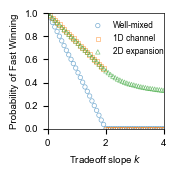

In [ ]:
ks = np.linspace(0, 4, 51)
fig, ax = plt.subplots(figsize=(1.5, 1.5))
oc = outcomes_kbscan_0d
ax.scatter(ks, oc[:,0,0], lw=0.5, color='none', edgecolors='tab:blue', s=10, marker='o', alpha=0.6, label='Well-mixed')
oc = outcomes_kbscan_1d
ax.scatter(ks, oc[:,0,0], lw=0.5, color='none', edgecolors='tab:orange', s=10, marker='s', alpha=0.6, label='1D channel')
oc = outcomes_kbscan_2d
ax.scatter(ks, oc[:,0,0]+oc[:,0,1], lw=0.5, color='none', edgecolors='tab:green', s=10, marker='^', alpha=0.6, label='2D expansion')
ax.set_ylim(0,1)
ax.set_xlim(0,4)
ax.set_ylabel('Probability')
ax.set_xlabel('Tradeoff slope '+r'$k$')
ax.legend(loc=(0.33, 0.6), fontsize=6, frameon=False)
fig.savefig('./Fig4/4c_f1.pdf', bbox_inches='tight', transparent=True)

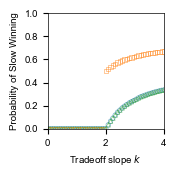

In [ ]:
ks = np.linspace(0, 4, 51)
fig, ax = plt.subplots(figsize=(1.5, 1.5))
oc = outcomes_kbscan_0d
ax.scatter(ks, oc[:,0,3], lw=0.5, color='none', edgecolors='tab:blue', s=10, marker='o', alpha=0.6, label='Well-mixed')
#ax.plot(ks, oc[:,0,3], lw=0.5, color='tab:blue', alpha=0.6)
oc = outcomes_kbscan_1d
ax.scatter(ks, oc[:,0,3], lw=0.5, color='none', edgecolors='tab:orange', s=10, marker='s', alpha=0.6, label='1D channel')
#ax.plot(ks, oc[:,0,3], lw=0.5, color='tab:orange', alpha=0.6)
oc = outcomes_kbscan_2d
ax.scatter(ks, oc[:,0,3], lw=0.5, color='none', edgecolors='tab:green', s=10, marker='^', alpha=0.6, label='2D expansion')
ax.set_ylim(0,1)
ax.set_xlim(0,4)
ax.set_ylabel('Probability')
ax.set_xlabel('Tradeoff slope '+r'$k$')
#ax.legend()
fig.savefig('./Fig4/4c_s1.pdf', bbox_inches='tight', transparent=True)

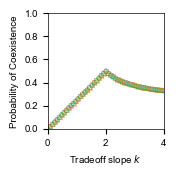

In [ ]:
ks = np.linspace(0, 4, 51)
fig, ax = plt.subplots(figsize=(1.5, 1.5))
oc = outcomes_kbscan_0d
ax.scatter(ks, oc[:,0,2], lw=0.5, color='none', edgecolors='tab:blue', s=10, marker='o', alpha=0.6, label='Well-mixed')
oc = outcomes_kbscan_1d
ax.scatter(ks, oc[:,0,2], lw=0.5, color='none', edgecolors='tab:orange', s=10, marker='s', alpha=0.6, label='1D channel')
oc = outcomes_kbscan_2d
ax.scatter(ks, oc[:,0,2], lw=0.5, color='none', edgecolors='tab:green', s=10, marker='^', alpha=0.6, label='2D expansion')
ax.set_ylim(0,1)
ax.set_xlim(0,4)
ax.set_ylabel('Probability')
ax.set_xlabel('Tradeoff slope '+r'$k$')
#ax.legend()
fig.savefig('./Fig4/4c_c1.pdf', bbox_inches='tight', transparent=True)

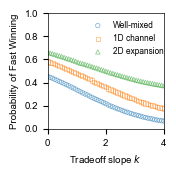

In [ ]:
ks = np.linspace(0, 4, 51)
fig, ax = plt.subplots(figsize=(1.5, 1.5))
oc = outcomes_kbscan_0d
ax.scatter(ks, oc[:,-1,0], lw=0.5, color='none', edgecolors='tab:blue', s=10, marker='o', alpha=0.6, label='Well-mixed')
oc = outcomes_kbscan_1d
ax.scatter(ks, oc[:,-1,0], lw=0.5, color='none', edgecolors='tab:orange', s=10, marker='s', alpha=0.6, label='1D channel')
oc = outcomes_kbscan_2d
ax.scatter(ks, oc[:,-1,0]+oc[:,-1,1], lw=0.5, color='none', edgecolors='tab:green', s=10, marker='^', alpha=0.6, label='2D expansion')
ax.set_ylim(0,1)
ax.set_xlim(0,4)
ax.set_ylabel('Probability')
ax.set_xlabel('Tradeoff slope '+r'$k$')
ax.legend(loc=(0.33, 0.6), fontsize=6, frameon=False)
fig.savefig('./Fig4/4c_f2.pdf', bbox_inches='tight', transparent=True)

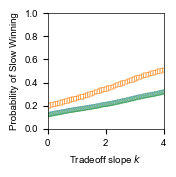

In [ ]:
ks = np.linspace(0, 4, 51)
fig, ax = plt.subplots(figsize=(1.5, 1.5))
oc = outcomes_kbscan_0d
ax.scatter(ks, oc[:,-1,3], lw=0.5, color='none', edgecolors='tab:blue', s=10, marker='o', alpha=0.6, label='Well-mixed')
#ax.plot(ks, oc[:,0,3], lw=0.5, color='tab:blue', alpha=0.6)
oc = outcomes_kbscan_1d
ax.scatter(ks, oc[:,-1,3], lw=0.5, color='none', edgecolors='tab:orange', s=10, marker='s', alpha=0.6, label='1D habitat')
#ax.plot(ks, oc[:,0,3], lw=0.5, color='tab:orange', alpha=0.6)
oc = outcomes_kbscan_2d
ax.scatter(ks, oc[:,-1,3], lw=0.5, color='none', edgecolors='tab:green', s=10, marker='^', alpha=0.6, label='2D expansion')
ax.set_ylim(0,1)
ax.set_xlim(0,4)
ax.set_ylabel('Probability')
ax.set_xlabel('Tradeoff slope '+r'$k$')
#ax.legend()
fig.savefig('./Fig4/4c_s2.pdf', bbox_inches='tight', transparent=True)

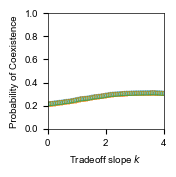

In [ ]:
ks = np.linspace(0, 4, 51)
fig, ax = plt.subplots(figsize=(1.5, 1.5))
oc = outcomes_kbscan_0d
ax.scatter(ks, oc[:,-1,2], lw=0.5, color='none', edgecolors='tab:blue', s=10, marker='o', alpha=0.6, label='Well-mixed')
oc = outcomes_kbscan_1d
ax.scatter(ks, oc[:,-1,2], lw=0.5, color='none', edgecolors='tab:orange', s=10, marker='s', alpha=0.6, label='1D habitat')
oc = outcomes_kbscan_2d
ax.scatter(ks, oc[:,-1,2], lw=0.5, color='none', edgecolors='tab:green', s=10, marker='^', alpha=0.6, label='2D expansion')
ax.set_ylim(0,1)
ax.set_xlim(0,4)
ax.set_ylabel('Probability')
ax.set_xlabel('Tradeoff slope '+r'$k$')
#ax.legend()
fig.savefig('./Fig4/4c_c2.pdf', bbox_inches='tight', transparent=True)

# Fig. 4c

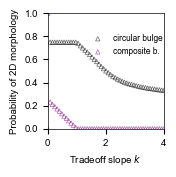

In [24]:
ks = np.linspace(0, 4, 51)
fig, ax = plt.subplots(figsize=(1.5, 1.5))
oc = outcomes_kbscan_2d
# 0: composite, 1: circular
ax.scatter(ks, oc[:,0,1], lw=0.5, color='none', edgecolors='k', s=10, marker='^', alpha=0.6, label='circular bulge')
ax.scatter(ks, oc[:,0,0], lw=0.5, color='none', edgecolors='purple', s=10, marker='^', alpha=0.6, label='composite b.')
ax.set_ylim(0,1)
ax.set_xlim(0,4)
ax.set_ylabel('Probability of 2D morphology')
ax.set_xlabel('Tradeoff slope '+r'$k$')
ax.legend(loc=(0.33, 0.6), fontsize=6, frameon=False)
fig.savefig('./Fig4/4d_1.pdf', bbox_inches='tight', transparent=True)

In [ ]:
date = "250501_L400_T600"
code = 'S1fraction'
nbin_a = 41

fname = "horizontal_a21_-0.2"
f = h5py.File(dir1 + code + '/'+ date + '/' + fname + '_hss.h5', "r"); hss = f["hss"][:]; f.close()
f = h5py.File(dir1 + code + '/'+ date + '/' + fname + '_fss.h5', "r"); fss = f["fss"][:]; f.close()
hss1 = hss.swapaxes(2,0); #hss = hss.swapaxes(2,1)
fss1 = fss.swapaxes(2,0); #fss = fss.swapaxes(2,1)

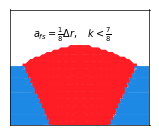

In [34]:
f1 = 0.5; f2 = 0.5;
i = 21
nbin_a = 41
asfs = np.linspace(-0.5, 0.5, nbin_a)
xs = np.linspace(0, 1, 401)

hs = hss1[i]; fs=fss1[i]; 
fig, a = plt.subplots(figsize=(1.5*2*0.6,0.75*2))
nl = 100
h = hs[200:,nl]; f = fs[200:,nl]; 
xb = np.max(xs[200:][f>f2])
hb = np.max(h[f<f1])
a.set_xticks([]); a.set_yticks([])
for tt in np.arange(nl):
    t = tt+1
    h = hs[200:,t]; f = fs[200:,t]; 
    a.plot( xs[200:][f>f2], h[f>f2], color=red, alpha=1, lw=2.0)
    a.plot( xs[200:][f<f1], h[f<f1], color=blue, alpha=1, lw=2.0)
    a.plot( 1-xs[200:][f>f2], h[f>f2], color=red, alpha=1, lw=2.0)
    a.plot( 1-xs[200:][f<f1], h[f<f1], color=blue, alpha=1, lw=2.0)
a.set_xlim(0.25+0.125+0.05, 0.75-0.125-0.05)
a.set_ylim(hb-100*0.5/2,hb+100*0.5/2)
a.text(0.5-0.05, hb+13, r'$a_{fs} =\frac{1}{8} \Delta r, \quad k < \frac{7}{8}$')
#a.arrow( xb, hb, 0.1, 0, length_includes_head=True, head_width=0.3, linewidth=0.1, shape='full', facecolor='black')

fig.savefig('./Fig4/4d_u1.pdf', bbox_inches='tight', transparent=True)

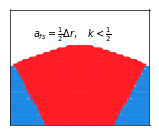

In [33]:
f1 = 0.5; f2 = 0.5;
i = 24
nbin_a = 41
asfs = np.linspace(-0.5, 0.5, nbin_a)
xs = np.linspace(0, 1, 401)

hs = hss1[i]; fs=fss1[i]; 
fig, a = plt.subplots(figsize=(1.5*2*0.6,0.75*2))
nl = 100
h = hs[200:,nl]; f = fs[200:,nl]; 
xb = np.max(xs[200:][f>f2])
hb = np.max(h[f<f1])
a.set_xticks([]); a.set_yticks([])
for tt in np.arange(nl):
    t = tt+1
    h = hs[200:,t]; f = fs[200:,t]; 
    a.plot( xs[200:][f>f2], h[f>f2], color=red, alpha=1, lw=2.0)
    a.plot( xs[200:][f<f1], h[f<f1], color=blue, alpha=1, lw=2.0)
    a.plot( 1-xs[200:][f>f2], h[f>f2], color=red, alpha=1, lw=2.0)
    a.plot( 1-xs[200:][f<f1], h[f<f1], color=blue, alpha=1, lw=2.0)
a.set_xlim(0.25+0.125+0.05, 0.75-0.125-0.05)
a.set_ylim(hb-100*0.5/2,hb+100*0.5/2)
a.text(0.5-0.05, hb+13, r'$a_{fs} =\frac{1}{2} \Delta r, \quad k < \frac{1}{2}$')
#a.arrow( xb, hb, 0.1, 0, length_includes_head=True, head_width=0.3, linewidth=0.1, shape='full', facecolor='black')

fig.savefig('./Fig4/4d_u2.pdf', bbox_inches='tight', transparent=True)